In [5]:
% some housekeeping stuff
clear
graphics_toolkit ("plotly")
warning off
format short e
% end of housekeeping

Start with 0.001 M acetic acid.  We know the pH can be determined by solving the quadratic to determine H+.  the quadratic (we derived before)

a=1, b=Ka, c=-KaAT

we will run ionic strength from 0.01 to 0.5 and see how pH changes.  Experimentally we would do this by adding an ionic strength buffer ... we can't do an ionic strength buffer less than 0.01 because of the "rule of thumb" that an ionic strength buffer needs to be at least 10X higher in conc than the other species.  At 0.001 total acid we would defintely have less than 0.001 molar charged ions so we are safe here (even if acetic acid were a strong acid and it is of course a weak acid).

For each ionic strength we simply change the Ka value from the thermodynamic value to a new value conditional on ionic strength.  then solve for pH as usual.  Beause we are doing things the "thermodynamically correct way" we also will convert the final pH to make sure we reporting pH in activity not concentration units (definition of pH = -log(H+)).

we need to look up the size parameter.  for H+ this is 900 pm.  For Ac- this is 450 pm.  HAc is neutral so no correction needed, gamma(HAc)=1 and (HAc)=[HAc].

to do the Ka correction ...

$$K_a^{thermo}=\dfrac{(H^+)(Ac^-)}{(HAc)} $$

sub in definition of activity

$$K_a^{thermo}=\dfrac{\gamma_H[H^+]\gamma_{Ac}[Ac^-]}{\gamma_{HAc}[HAc]} $$

pull out the constant terms and put in $\gamma_{HAc}=1$

$$K_a^{thermo}=\dfrac{\gamma_H\gamma_{Ac}}{1}\times \dfrac{[H^+][Ac^-]}{[HAc]} $$

notice that the ratio of products over reactants is the concentraition equilibrium constant

$$K_a^{thermo}=\dfrac{\gamma_H\gamma_{Ac}}{1}\times K_a^{conc} $$

solve for $K_a^{conc}$

$$K_a^{conc}=\dfrac{ K_a^{thermo}}{\gamma_H\gamma_{Ac}} $$



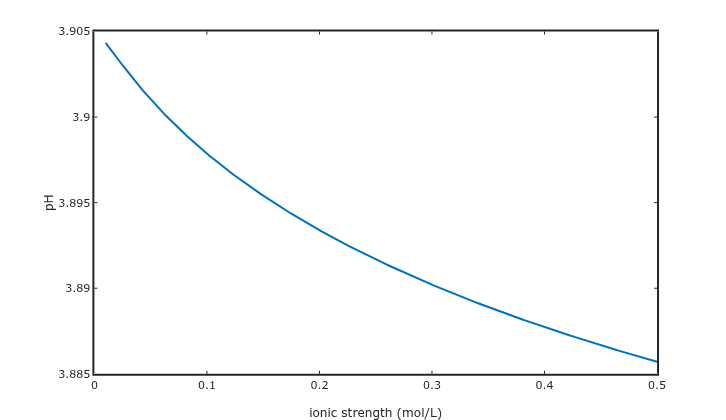

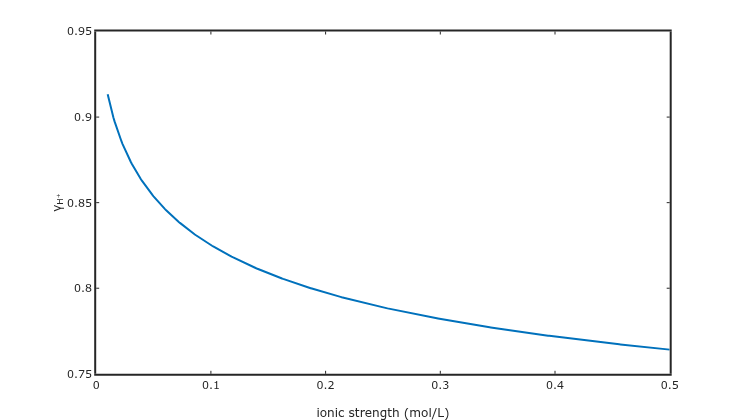

In [6]:
Ka=10^-4.75; u=0.01:0.001:0.5; AT=0.001;

for i=1:length(u)
    loggammaH=-0.51*sqrt(u(i))/(1+900*sqrt(u(i))/305);gammaH(i)=10^loggammaH;
    loggammaAc=-0.51*sqrt(u(i))/(1+450*sqrt(u(i))/305);gammaAc=10^loggammaAc;
    Kaconc=Ka/(gammaH(i)*gammaAc);
    a=1;
    b=Kaconc;
    c=-Kaconc*AT;
    t=roots([a b c]); H=t(real(t)>0&imag(t)==0);
    pH(i)=-log10(H*gammaH(i));    
end

figure(1); plot(u,pH,'linewidth',2)
xlabel('ionic strength (mol/L)'); ylabel('pH'); set(gca,'linewidth',2,'fontsize',11)

figure(2); plot(u,gammaH,'linewidth',2); 
xlabel('ionic strength (mol/L)'); ylabel('\gamma_{H^+}'); set(gca,'linewidth',2,'fontsize',11)
